In [2]:
import pandas as pd
import matplotlib.pyplot as plt
df=pd.read_csv("/content/Walmart_Sales.csv")

# Convert Date text (day-month-year) into real dates and add helper columns
df["Date"]=pd.to_datetime(df["Date"], dayfirst=True)
df["Year"]=df["Date"].dt.year
df["Month"]=df["Date"].dt.to_period("M")

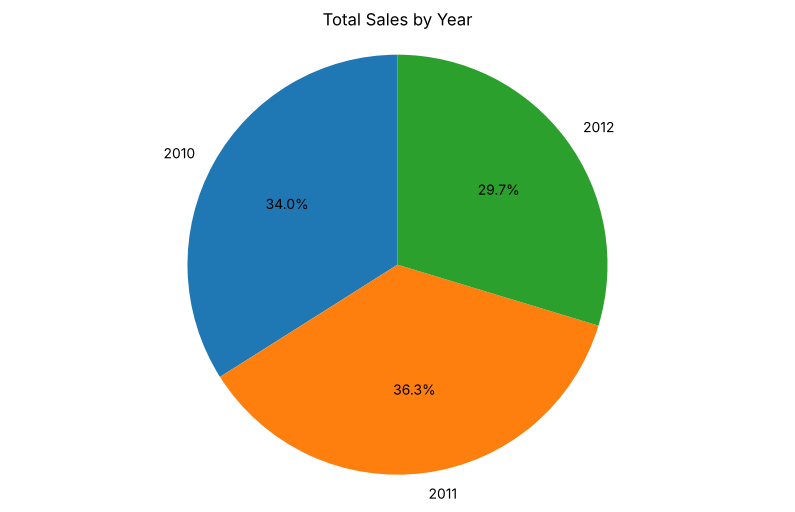

In [3]:
# CHART 1: Pie chart  (was: Quantity Sold by Brand)
year_sales=df.groupby("Year")["Weekly_Sales"].sum()

plt.figure(figsize=(10,6))
plt.pie(year_sales, labels=year_sales.index, autopct='%1.1f%%', startangle=90)
plt.title("Total Sales by Year")
plt.axis("equal")
plt.savefig("Total Sales by Year.png")
plt.show()

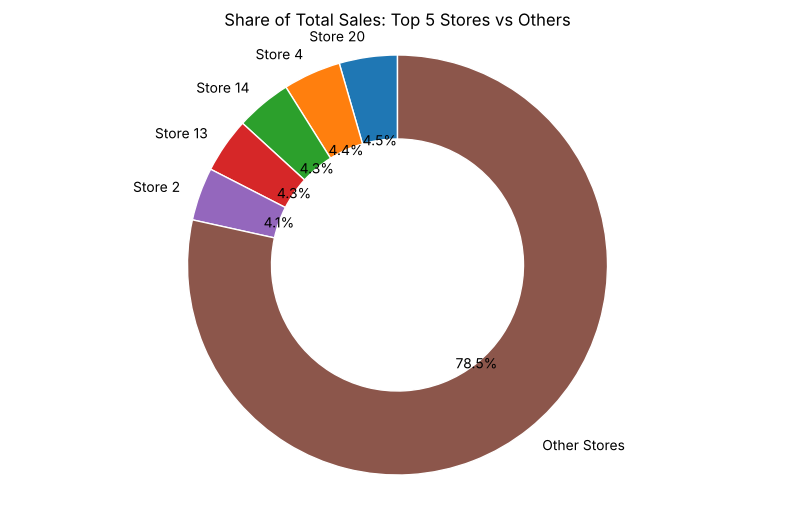

In [4]:
# CHART 2: Donut chart  (same plt.pie function + a hole using wedgeprops)
store_sales=df.groupby("Store")["Weekly_Sales"].sum().sort_values(ascending=False)
top5=store_sales.head(5)
top5["Other Stores"]=store_sales.iloc[5:].sum()

plt.figure(figsize=(10,6))
plt.pie(top5, labels=[f"Store {s}" if s!="Other Stores" else s for s in top5.index],
        autopct='%1.1f%%', startangle=90, wedgeprops={"width":0.4, "edgecolor":"white"})
plt.title("Share of Total Sales: Top 5 Stores vs Others")
plt.axis("equal")
plt.savefig("Top 5 Stores Donut.png")
plt.show()

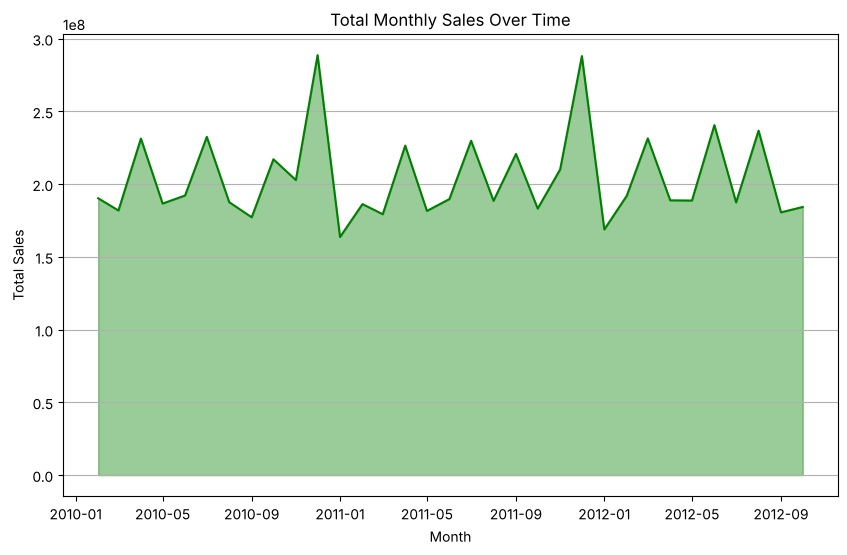

In [5]:
# CHART 3: Area chart  (total sales per month)
monthly_sales=df.groupby("Month")["Weekly_Sales"].sum()
x=monthly_sales.index.to_timestamp()

plt.figure(figsize=(10,6))
plt.fill_between(x, monthly_sales.values, color="Green", alpha=0.4)
plt.plot(x, monthly_sales.values, color="Green")
plt.title("Total Monthly Sales Over Time")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.grid(axis="y")
plt.savefig("Monthly Sales Area Chart.png")
plt.show()

In [6]:
# 12 BUILT-IN FUNCTIONS applied to the dataset
sales=list(df["Weekly_Sales"])                       # 1. list()
stores=set(df["Store"])                              # 2. set()

print("Number of rows:", len(df))                    # 3. print()  4. len()
print("Number of stores:", len(stores))
print("Highest weekly sales:", max(sales))           # 5. max()
print("Lowest weekly sales:", min(sales))            # 6. min()
print("Total sales:", round(sum(sales), 2))          # 7. sum()  8. round()
print("Average weekly sales:", round(sum(sales)/len(sales), 2))

top3=sorted(sales, reverse=True)[:3]                 # 9. sorted()
print("Top 3 weekly sales:", top3)

print("Type of the sales column:", type(sales))      # 10. type()

for i, s in enumerate(sorted(stores)[:3]):           # 11. enumerate()
    print("Index", i, "-> Store", s)

for st, sl in zip(df["Store"][:3], df["Weekly_Sales"][:3]):   # 12. zip()
    print("Store", st, "sold", sl)

Number of rows: 6435
Number of stores: 45
Highest weekly sales: 3818686.45
Lowest weekly sales: 209986.25
Total sales: 6737218987.11
Average weekly sales: 1046964.88
Top 3 weekly sales: [3818686.45, 3766687.43, 3749057.69]
Type of the sales column: <class 'list'>
Index 0 -> Store 1
Index 1 -> Store 2
Index 2 -> Store 3
Store 1 sold 1643690.9
Store 1 sold 1641957.44
Store 1 sold 1611968.17
